# Climate Comfort Index: XGBoost experiment

Student **25945320**. Predicts CCI at **+1, +2 and +3 days** from the leakage-audited features
built by the preprocessing notebook.

## Hypothesis

Gradient-boosted trees will predict CCI more accurately than a Random Forest, a persistence
forecast and a seasonal climatology at all three horizons, because boosting fits residuals
sequentially and can exploit weak signal that bagging averages away.

The competing possibility is explicitly entertained: with roughly 2,900 training rows and a low
persistence correlation at *t*+3, boosting may overfit where bagging does not. Early stopping on
the validation split is used to detect this, and the stopping round is reported as evidence
either way.

## Design

| Choice | Value | Reason |
|---|---|---|
| Algorithm | `XGBRegressor`, `hist` tree method | Strong tabular performance; fast on a dataset this size |
| Strategy | One model per horizon, plus a `multi_output_tree` comparison | The endpoint returns three values; both routes are evaluated |
| Early stopping | On validation MAE, 50 rounds patience | Boosting will overfit given enough rounds; the stopping round quantifies how much signal exists |
| Scaling | None | Trees split on thresholds |
| Selection data | Validation split (2024) | The test split is not read in this notebook |
| Metrics | MAE, RMSE, R², prediction spread | Spread detects a model retreating to the mean |
| Baselines | Persistence and seasonal climatology | Beating both is the minimum bar for deployment |

## A note on early stopping and the validation split

Validation data is used both to stop boosting and to report performance. That is a mild optimism
bias: the reported validation error is slightly better than a truly unseen estimate would be.

It is accepted here rather than hidden, for two reasons. The alternative — carving a third split
from an already small training set — costs more in fitting data than it buys in cleanliness. And
the honest final estimate comes from the test split, which no notebook in this project has
touched. The bias is noted here so that it is not mistaken for a genuine advantage over the
Random Forest, which requires no such tuning signal.


In [1]:
from __future__ import annotations

import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 25945320


def project_root(start: Path | None = None) -> Path:
    """Return the project directory containing ``pyproject.toml``."""
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root from the current directory.")


PROJECT_ROOT = project_root()
DATA_DIR = PROJECT_ROOT / "data" / "processed" / "comfort_climate"
MODEL_DIR = PROJECT_ROOT / "models" / "comfort_climate" / "experiments"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "comfort_climate"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

METADATA = json.loads((DATA_DIR / "cci_feature_metadata.json").read_text())
FEATURE_COLUMNS = METADATA["feature_columns"]
FEATURE_GROUPS = METADATA["feature_groups"]
TARGET_COLUMNS = METADATA["target_columns"]
HORIZONS = METADATA["horizons_days"]
PERSISTENCE_COLUMN = "cci"

EXPERIMENT = "cci_xgboost"
ALGORITHM_NAME = "XGBoost Regressor"
MODEL_LABEL = "xgboost"

print(f"Features: {len(FEATURE_COLUMNS)} across {len(FEATURE_GROUPS)} families")
print(f"Targets:  {', '.join(TARGET_COLUMNS)}")
print(f"Groups:   {', '.join(FEATURE_GROUPS)}")


Features: 86 across 8 families
Targets:  cci_t1, cci_t2, cci_t3
Groups:   same_day_observations, same_day_scores, lags, rolling_statistics, rolling_precipitation, rolling_gusts, deltas, seasonal


## 1. Load chronological splits

Only the training and validation files are read. **`sydney_cci_test.csv` is never loaded in this
notebook.** It is reserved for a single final evaluation once a model has been selected, so that
no repeated look at the test period can inform any decision made here.

The preprocessing notebook already applied the chronological split, the warm-up filter and the
3-day embargo at each boundary. Nothing is re-split or shuffled here.


In [2]:
def load_split(name: str) -> pd.DataFrame:
    """Read one chronological split and verify it carries the expected columns."""
    path = DATA_DIR / f"sydney_cci_{name}.csv"
    frame = (
        pd.read_csv(path, parse_dates=["feature_date"])
        .set_index("feature_date")
        .sort_index()
    )
    required = [*FEATURE_COLUMNS, *TARGET_COLUMNS, PERSISTENCE_COLUMN]
    missing = [column for column in required if column not in frame.columns]
    if missing:
        raise ValueError(f"{path.name} is missing columns: {missing[:5]}")
    return frame


splits = {name: load_split(name) for name in ("train", "val")}
X = {name: frame[FEATURE_COLUMNS] for name, frame in splits.items()}
y = {name: frame[TARGET_COLUMNS] for name, frame in splits.items()}

if splits["train"].index.max() >= splits["val"].index.min():
    raise AssertionError("Training dates overlap the validation period.")

for name, frame in splits.items():
    print(f"{name:5} {len(frame):5,} rows  {frame.index.min():%Y-%m-%d} to "
          f"{frame.index.max():%Y-%m-%d}")
print("\nTest split deliberately not loaded.")


train 2,889 rows  2016-01-31 to 2023-12-28
val     363 rows  2024-01-01 to 2024-12-28

Test split deliberately not loaded.


## 2. Baselines

Two reference forecasts. A model that fails to beat both of them is not worth deploying, whatever
its absolute error looks like.

**Persistence** carries today's CCI forward unchanged. It is the natural naive forecast for an
autocorrelated series and is strong at short horizons.

**Climatology** predicts the training-set average CCI for that day of the year, smoothed with a
15-day centred window to suppress sampling noise. It encodes the seasonal cycle and nothing else.
Centring is acceptable here because the smoothing is applied to a day-of-year profile derived
solely from training data, not to the time series itself — no future observation enters any
prediction.

The two are complementary: persistence knows about the current weather but not the season,
climatology knows the season but not the weather. Beating both means the model has combined
them, which is the minimum bar for a useful forecast.


In [3]:
def climatology_profile(frame: pd.DataFrame, target: str, window: int = 15) -> pd.Series:
    """Mean target by day of year from the training split, smoothed and wrapped at year end."""
    profile = frame.groupby(frame.index.dayofyear)[target].mean().reindex(range(1, 367))
    profile = profile.interpolate(limit_direction="both")
    # Concatenating three copies lets the rolling window wrap across the year boundary.
    wrapped = pd.concat([profile, profile, profile])
    smoothed = wrapped.rolling(window, center=True, min_periods=1).mean()
    return smoothed.iloc[len(profile):2 * len(profile)].set_axis(profile.index)


CLIMATOLOGY = {target: climatology_profile(splits["train"], target) for target in TARGET_COLUMNS}


def baseline_predictions(name: str, target: str) -> dict[str, np.ndarray]:
    """Return persistence and climatology forecasts for one split and horizon."""
    frame = splits[name]
    return {
        "persistence": frame[PERSISTENCE_COLUMN].to_numpy(),
        "climatology": CLIMATOLOGY[target].reindex(frame.index.dayofyear).to_numpy(),
    }


def regression_metrics(y_true, y_pred) -> dict[str, float]:
    """MAE, RMSE, R2 and prediction spread on the 0-100 CCI scale."""
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "r2": float(r2_score(y_true, y_pred)),
        "pred_std": float(np.std(y_pred)),
    }


baseline_rows = []
for target in TARGET_COLUMNS:
    for label, prediction in baseline_predictions("val", target).items():
        baseline_rows.append(
            {"target": target, "model": label,
             **regression_metrics(splits["val"][target], prediction)}
        )
BASELINES = pd.DataFrame(baseline_rows).set_index(["target", "model"])
print("Validation baselines (the floors any model must clear):\n")
BASELINES


Validation baselines (the floors any model must clear):



mae   rmse     r2  pred_std
target model                                    
cci_t1 persistence 7.562  9.928  0.185    10.937
       climatology 7.627 10.135  0.151     3.723
cci_t2 persistence 8.624 11.521 -0.094    10.937
       climatology 7.640 10.141  0.152     3.722
cci_t3 persistence 9.162 12.015 -0.188    10.937
       climatology 7.651 10.143  0.153     3.720

## 3. Per-horizon models with early stopping

Three boosters, one per horizon, each stopped when validation MAE has not improved for 50 rounds.

`n_estimators` is set deliberately high and left to early stopping to truncate. The round at
which each model stops is itself a result worth reporting: a model that stops after very few
rounds has found little to fit beyond the obvious, which is the signature of a weak-signal
problem rather than a badly configured one. Expect the *t*+3 model to stop earlier than *t*+1.


cci_t1: stopped at round 175 of 3000, best validation MAE 6.340
cci_t2: stopped at round 130 of 3000, best validation MAE 7.191
cci_t3: stopped at round 114 of 3000, best validation MAE 7.373


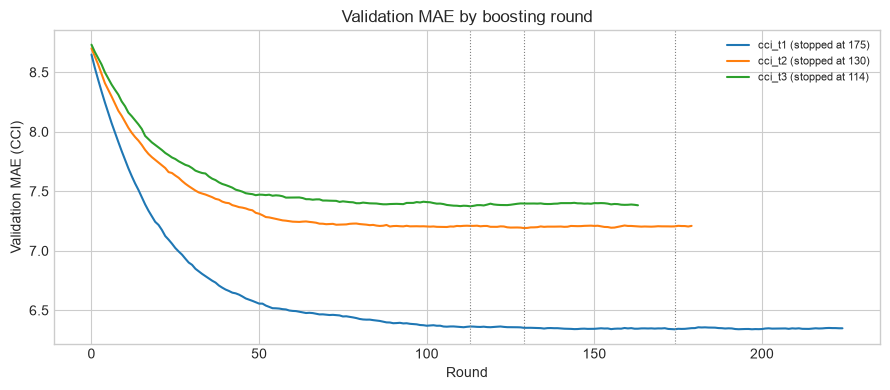

In [4]:
BASE_PARAMS = {
    "n_estimators": 3000,
    "learning_rate": 0.03,
    "max_depth": 4,
    "min_child_weight": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.6,
    "reg_lambda": 1.0,
    "tree_method": "hist",
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
    "eval_metric": "mae",
    "early_stopping_rounds": 50,
}


def fit_per_horizon(params: dict, verbose: bool = True) -> dict[int, XGBRegressor]:
    """Fit one booster per horizon, stopping each on its own validation MAE."""
    fitted = {}
    for h in HORIZONS:
        target = f"cci_t{h}"
        model = XGBRegressor(**params)
        model.fit(
            X["train"][FEATURE_COLUMNS], y["train"][target],
            eval_set=[(X["val"][FEATURE_COLUMNS], y["val"][target])],
            verbose=False,
        )
        fitted[h] = model
        if verbose:
            print(f"cci_t{h}: stopped at round {model.best_iteration + 1} "
                  f"of {params['n_estimators']}, best validation MAE {model.best_score:.3f}")
    return fitted


models = fit_per_horizon(BASE_PARAMS)

fig, axis = plt.subplots(figsize=(9, 4))
for h in HORIZONS:
    curve = models[h].evals_result()["validation_0"]["mae"]
    axis.plot(curve, label=f"cci_t{h} (stopped at {models[h].best_iteration + 1})")
    axis.axvline(models[h].best_iteration, ls=":", lw=0.8, color="grey")
axis.set(title="Validation MAE by boosting round", xlabel="Round", ylabel="Validation MAE (CCI)")
axis.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"{EXPERIMENT}-boosting-curves.png", dpi=150, bbox_inches="tight")
plt.show()


### 3b. The `multi_output_tree` alternative

XGBoost 2.0 and later can build trees with vector-valued leaves, predicting all three horizons
from a single tree structure. This differs from the default `one_output_per_tree`, which is
equivalent to three independent models.

Vector leaves produce a considerably smaller artefact and can help when targets are strongly
correlated, as these are. The risk is that a single tree structure must compromise between three
horizons with genuinely different signal-to-noise ratios. The comparison is run rather than
assumed; if the multi-output variant is unavailable in the installed version, the cell reports
that and continues.


In [5]:
multi_metrics = None
try:
    multi_params = {k: v for k, v in BASE_PARAMS.items() if k != "early_stopping_rounds"}
    multi_params.update({"multi_strategy": "multi_output_tree", "n_estimators": 400})
    multi_model = XGBRegressor(**multi_params)
    multi_model.fit(X["train"][FEATURE_COLUMNS], y["train"][TARGET_COLUMNS], verbose=False)
    multi_prediction = multi_model.predict(X["val"][FEATURE_COLUMNS])

    rows = []
    for index, h in enumerate(HORIZONS):
        target = f"cci_t{h}"
        rows.append({"target": target, "strategy": "per-horizon (early stopped)",
                     **regression_metrics(splits["val"][target],
                                          models[h].predict(X["val"][FEATURE_COLUMNS]))})
        rows.append({"target": target, "strategy": "multi_output_tree",
                     **regression_metrics(splits["val"][target], multi_prediction[:, index])})
    multi_metrics = pd.DataFrame(rows).set_index(["target", "strategy"])
    print(multi_metrics.to_string())
    print("\nPer-horizon models are carried forward: they expose separate importances per "
          "horizon and support early stopping, which the vector-leaf variant does not.")
except (TypeError, ValueError) as error:
    print(f"multi_output_tree unavailable in this XGBoost version: {error}")


                                     mae  rmse    r2  pred_std
target strategy                                               
cci_t1 per-horizon (early stopped) 6.340 8.363 0.422     6.561
       multi_output_tree           6.496 8.490 0.404     6.438
cci_t2 per-horizon (early stopped) 7.191 9.462 0.262     4.760
       multi_output_tree           7.344 9.557 0.247     5.091
cci_t3 per-horizon (early stopped) 7.373 9.813 0.207     4.490
       multi_output_tree           7.507 9.886 0.196     4.623

Per-horizon models are carried forward: they expose separate importances per horizon and support early stopping, which the vector-leaf variant does not.


## 4. Feature-group ablation

The preprocessing notebook recorded which engineered family each column belongs to. Families are
added cumulatively and the model refitted at each step, so the contribution of each block of
engineering is measured rather than assumed.

The sequence starts from persistence alone — a single column, today's CCI — and builds up. A
family that does not move validation error is not earning its place in the deployed model, and
dropping it produces a smaller artefact and a cleaner feature-importance table.

Default hyperparameters are used throughout this section so that differences are attributable to
the feature set rather than to tuning. The ablation is scored on **validation** data only.


Validation MAE by cumulative feature set (lower is better):

target                   n_features  cci_t1  cci_t2  cci_t3
config                                                     
persistence only                  1   7.162   7.811   8.133
+ same_day_observations           6   6.449   7.212   7.554
+ same_day_scores                12   6.501   7.468   7.492
+ lags                           40   6.524   7.324   7.463
+ rolling_statistics             72   6.458   7.343   7.646
+ rolling_precipitation          76   6.516   7.277   7.654
+ rolling_gusts                  80   6.493   7.499   7.766
+ deltas                         84   6.328   7.378   7.597
+ seasonal                       86   6.494   7.404   7.619


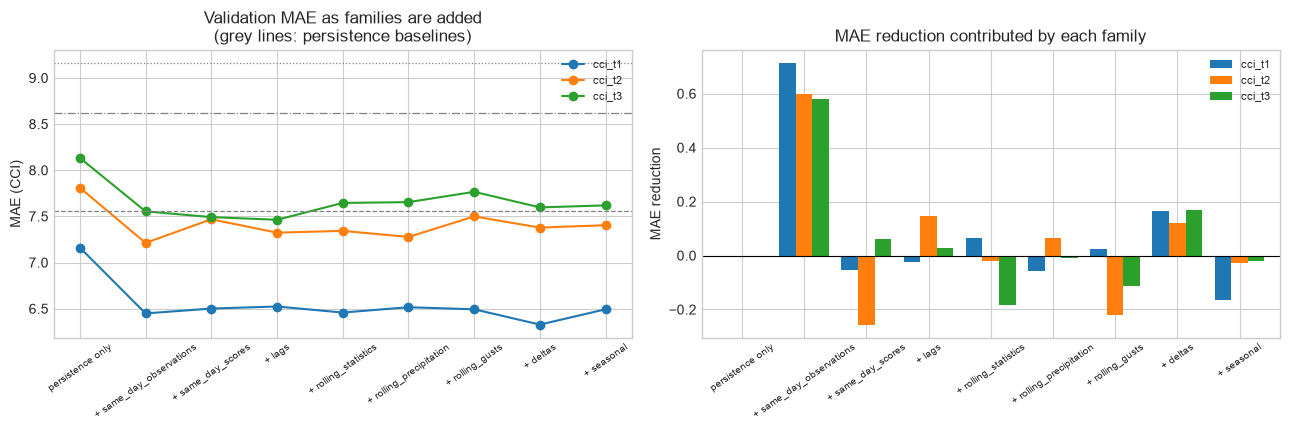

In [6]:
# Families are added in order of how much prior justification they have, so that each step asks
# "does this add anything beyond what is already present?"
GROUP_ORDER = [
    "same_day_observations", "same_day", "same_day_scores",
    "lags", "rolling_statistics", "rolling", "rolling_precipitation",
    "rolling_gusts", "deltas", "seasonal",
]
ordered_groups = [group for group in GROUP_ORDER if group in FEATURE_GROUPS]
ordered_groups += [group for group in FEATURE_GROUPS if group not in ordered_groups]

ablation_configs = {"persistence only": [PERSISTENCE_COLUMN]}
cumulative: list[str] = []
for group in ordered_groups:
    cumulative = cumulative + FEATURE_GROUPS[group]
    label = f"+ {group}"
    ablation_configs[label] = list(dict.fromkeys(cumulative))

ablation_rows = []
for label, columns in ablation_configs.items():
    for target in TARGET_COLUMNS:
        model = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4,
                             subsample=0.8, colsample_bytree=0.6,
                             tree_method="hist", random_state=RANDOM_STATE,
                             n_jobs=-1)
        model.fit(X["train"][columns], y["train"][target])
        prediction = model.predict(X["val"][columns])
        ablation_rows.append(
            {"config": label, "n_features": len(columns), "target": target,
              **regression_metrics(splits["val"][target], prediction)}
        )

ablation = pd.DataFrame(ablation_rows)
ablation_mae = ablation.pivot(index="config", columns="target", values="mae").reindex(
    ablation_configs
)
ablation_mae.insert(0, "n_features", [len(c) for c in ablation_configs.values()])
print("Validation MAE by cumulative feature set (lower is better):\n")
print(ablation_mae.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ablation_mae[TARGET_COLUMNS].plot(marker="o", ax=axes[0])
for target, style in zip(TARGET_COLUMNS, ("--", "-.", ":")):
    axes[0].axhline(BASELINES.loc[(target, "persistence"), "mae"], ls=style, lw=0.9,
                    color="grey")
axes[0].set(title="Validation MAE as families are added\n(grey lines: persistence baselines)",
            ylabel="MAE (CCI)", xlabel="")
axes[0].tick_params(axis="x", labelrotation=35, labelsize=7)
axes[0].legend(fontsize=8)

improvement = -ablation_mae[TARGET_COLUMNS].diff()
improvement.plot.bar(ax=axes[1], width=0.8)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(title="MAE reduction contributed by each family", ylabel="MAE reduction", xlabel="")
axes[1].tick_params(axis="x", labelrotation=35, labelsize=7)
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"{EXPERIMENT}-ablation.png", dpi=150, bbox_inches="tight")
plt.show()


## 4b. Hyperparameter search

A compact random search over the parameters that matter most for boosting on a small,
weak-signal dataset. Each candidate is fitted for all three horizons with early stopping, and
scored on mean validation MAE.

`max_depth` and `min_child_weight` control tree complexity and are the primary defence against
overfitting 2,900 rows. `subsample` and `colsample_bytree` add stochasticity, which matters here
because the feature set contains large blocks of near-duplicate columns that a deterministic
booster would repeatedly select from. `learning_rate` trades rounds for stability; low values
with early stopping are preferred to high values with few rounds.

The search is random rather than exhaustive to keep it honest — a large grid scored on 363
validation rows would select noise.


In [7]:
rng = np.random.default_rng(RANDOM_STATE)
N_CANDIDATES = 12

candidates = [
    {
        "max_depth": int(rng.choice([3, 4, 5, 6])),
        "min_child_weight": int(rng.choice([1, 5, 10, 20])),
        "subsample": float(rng.choice([0.6, 0.8, 1.0])),
        "colsample_bytree": float(rng.choice([0.4, 0.6, 0.8])),
        "learning_rate": float(rng.choice([0.01, 0.03, 0.05])),
        "reg_lambda": float(rng.choice([1.0, 5.0, 20.0])),
    }
    for _ in range(N_CANDIDATES)
]

search_rows = []
for candidate in candidates:
    params = {**BASE_PARAMS, **candidate}
    fitted = fit_per_horizon(params, verbose=False)
    maes = [
        mean_absolute_error(splits["val"][f"cci_t{h}"],
                            fitted[h].predict(X["val"][FEATURE_COLUMNS]))
        for h in HORIZONS
    ]
    search_rows.append({
        **candidate,
        "mean_val_mae": float(np.mean(maes)),
        "mean_best_round": float(np.mean([fitted[h].best_iteration + 1 for h in HORIZONS])),
    })

search = pd.DataFrame(search_rows).sort_values("mean_val_mae")
print(f"Random search over {N_CANDIDATES} candidates, best first:\n")
print(search.to_string(index=False))

BEST_PARAMS = {**BASE_PARAMS, **{
    key: search.iloc[0][key]
    for key in ("max_depth", "min_child_weight", "subsample", "colsample_bytree",
                "learning_rate", "reg_lambda")
}}
BEST_PARAMS["max_depth"] = int(BEST_PARAMS["max_depth"])
BEST_PARAMS["min_child_weight"] = int(BEST_PARAMS["min_child_weight"])
print(f"\nSelected: max_depth={BEST_PARAMS['max_depth']}, "
      f"min_child_weight={BEST_PARAMS['min_child_weight']}, "
      f"subsample={BEST_PARAMS['subsample']}, "
      f"colsample_bytree={BEST_PARAMS['colsample_bytree']}, "
      f"learning_rate={BEST_PARAMS['learning_rate']}, "
      f"reg_lambda={BEST_PARAMS['reg_lambda']}")

models = fit_per_horizon(BEST_PARAMS)


Random search over 12 candidates, best first:

 max_depth  min_child_weight  subsample  colsample_bytree  learning_rate  reg_lambda  mean_val_mae  mean_best_round
         3                 5      1.000             0.400          0.050       5.000         6.940          104.333
         4                 5      1.000             0.400          0.050       1.000         6.941           79.000
         3                20      0.800             0.400          0.030       5.000         6.948          179.333
         4                 5      1.000             0.800          0.010       1.000         6.950          309.667
         3                10      0.600             0.400          0.030       1.000         6.975          167.333
         6                20      0.600             0.800          0.050       1.000         6.977           72.333
         5                10      1.000             0.600          0.030       5.000         6.998          157.667
         6               

## 5. Evaluation against the baselines

Metrics for every horizon, against both baselines, on validation data.

`pred_std` is reported alongside the error metrics. It is the direct test for a model that has
retreated to predicting the mean: a spread far below the observed spread means the model is
declining to commit, which can produce a respectable MAE while being useless for identifying the
uncomfortable days a user actually cares about.

Expect error to grow with horizon. Atmospheric predictability decays, and the persistence
correlation measured during preprocessing fell sharply from *t*+1 to *t*+3, so a model that
performs equally well at all three horizons would be more suspicious than impressive.


Validation performance:

                     mae   rmse     r2  pred_std  observed_std
target model                                                  
cci_t1 xgboost     6.277  8.247  0.438     6.694        11.001
       persistence 7.562  9.928  0.185    10.937        11.001
       climatology 7.627 10.135  0.151     3.723        11.001
cci_t2 xgboost     7.144  9.465  0.262     4.657        11.014
       persistence 8.624 11.521 -0.094    10.937        11.014
       climatology 7.640 10.141  0.152     3.722        11.014
cci_t3 xgboost     7.400  9.857  0.200     4.398        11.023
       persistence 9.162 12.015 -0.188    10.937        11.023
       climatology 7.651 10.143  0.153     3.720        11.023

Improvement over each baseline (positive means the model is better):

                    mae_reduction relative
target baseline                           
cci_t1 persistence          1.285    17.0%
       climatology          1.351    17.7%
cci_t2 persistence          1.480    17

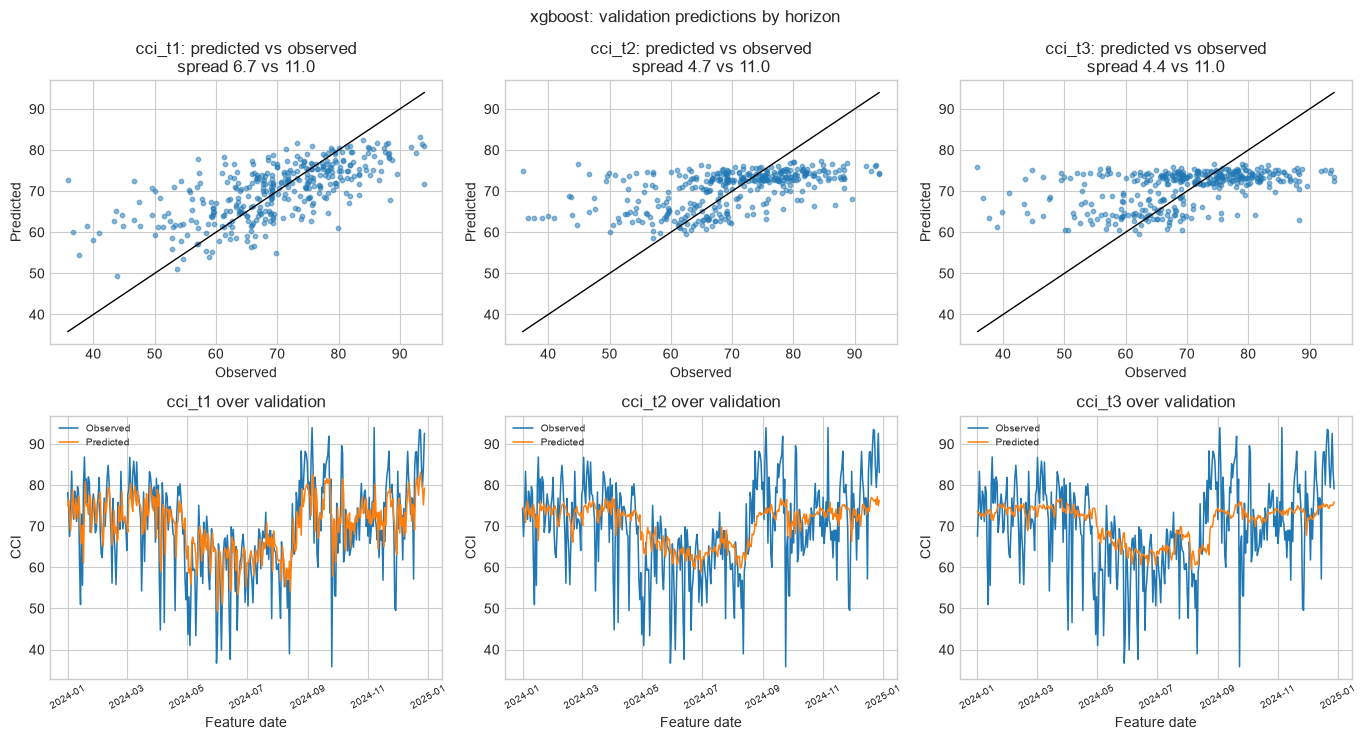

In [8]:
rows = []
predictions = {}
for h in HORIZONS:
    target = f"cci_t{h}"
    observed = splits["val"][target].to_numpy()
    prediction = models[h].predict(X["val"][FEATURE_COLUMNS])
    predictions[h] = prediction
    rows.append({"target": target, "model": MODEL_LABEL,
                 **regression_metrics(observed, prediction)})
    for label, baseline in baseline_predictions("val", target).items():
        rows.append({"target": target, "model": label,
                     **regression_metrics(observed, baseline)})

results = pd.DataFrame(rows).set_index(["target", "model"])
results["observed_std"] = [
    np.std(splits["val"][target]) for target in results.index.get_level_values(0)
]
print("Validation performance:\n")
print(results.to_string())

comparison = []
for h in HORIZONS:
    target = f"cci_t{h}"
    model_mae = results.loc[(target, MODEL_LABEL), "mae"]
    for baseline in ("persistence", "climatology"):
        baseline_mae = results.loc[(target, baseline), "mae"]
        comparison.append({
            "target": target, "baseline": baseline,
            "mae_reduction": baseline_mae - model_mae,
            "relative": (baseline_mae - model_mae) / baseline_mae,
        })
comparison = pd.DataFrame(comparison).set_index(["target", "baseline"])
print("\nImprovement over each baseline (positive means the model is better):\n")
print(comparison.to_string(formatters={"relative": "{:.1%}".format}))

fig, axes = plt.subplots(2, len(HORIZONS), figsize=(4.6 * len(HORIZONS), 7.5))
for column, h in enumerate(HORIZONS):
    target = f"cci_t{h}"
    observed = splits["val"][target].to_numpy()
    prediction = predictions[h]
    scatter_axis = axes[0, column]
    scatter_axis.scatter(observed, prediction, s=10, alpha=0.5)
    limits = [min(observed.min(), prediction.min()), max(observed.max(), prediction.max())]
    scatter_axis.plot(limits, limits, color="black", lw=1)
    scatter_axis.set(title=f"{target}: predicted vs observed\n"
                           f"spread {np.std(prediction):.1f} vs {np.std(observed):.1f}",
                     xlabel="Observed", ylabel="Predicted")
    series_axis = axes[1, column]
    series_axis.plot(splits["val"].index, observed, lw=1.1, label="Observed")
    series_axis.plot(splits["val"].index, prediction, lw=1.1, label="Predicted")
    series_axis.set(title=f"{target} over validation", xlabel="Feature date", ylabel="CCI")
    series_axis.tick_params(axis="x", labelrotation=30, labelsize=7)
    series_axis.legend(fontsize=7)
fig.suptitle(f"{MODEL_LABEL}: validation predictions by horizon", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"{EXPERIMENT}-validation.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Feature importance

Importances are read from the fitted per-horizon models and exported for the `/model-metadata`
endpoint.

One caveat governs how these should be read. Many of these features are strongly correlated —
`temperature_2m`, its four lags and its four rolling means all carry nearly the same signal. Tree
ensembles split that shared importance among the correlated group, so an individually
unimportant-looking feature may be part of a jointly essential block. Importance ranks features,
it does not prove any single one is dispensable; the ablation above is the more reliable guide to
what can be removed.

Comparing importances across horizons is informative in its own right. Features that rise in rank
from *t*+1 to *t*+3 are the ones carrying genuine forecast signal rather than persistence.


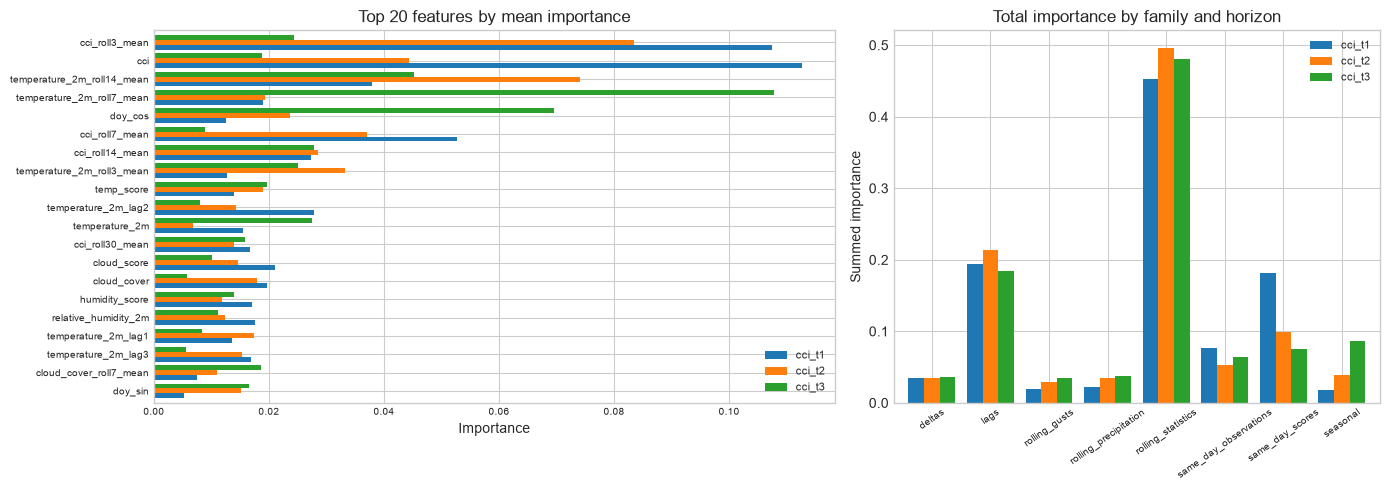

Share of total importance held by the top 10 features, per horizon:
  cci_t1: 44.3%
  cci_t2: 38.1%
  cci_t3: 38.4%


In [9]:
importances = pd.DataFrame(
    {f"cci_t{h}": pd.Series(models[h].feature_importances_, index=FEATURE_COLUMNS)
     for h in HORIZONS}
)
importances["mean"] = importances.mean(axis=1)
importances["family"] = [
    next(family for family, columns in FEATURE_GROUPS.items() if column in columns)
    for column in importances.index
]

top = importances.sort_values("mean", ascending=False).head(20)
family_totals = importances.groupby("family")[[f"cci_t{h}" for h in HORIZONS]].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.4, 1]})
top[[f"cci_t{h}" for h in HORIZONS]].iloc[::-1].plot.barh(ax=axes[0], width=0.8)
axes[0].set(title="Top 20 features by mean importance", xlabel="Importance")
axes[0].tick_params(labelsize=7)
axes[0].legend(fontsize=8)

family_totals.plot.bar(ax=axes[1], width=0.8)
axes[1].set(title="Total importance by family and horizon", ylabel="Summed importance",
            xlabel="")
axes[1].tick_params(axis="x", labelrotation=35, labelsize=7)
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"{EXPERIMENT}-importance.png", dpi=150, bbox_inches="tight")
plt.show()

print("Share of total importance held by the top 10 features, per horizon:")
for h in HORIZONS:
    column = f"cci_t{h}"
    share = importances[column].nlargest(10).sum() / importances[column].sum()
    print(f"  cci_t{h}: {share:.1%}")


## 7. Overfitting check

Boosting can drive training error arbitrarily low, so the training figures below are a
diagnostic rather than a result. Read them together with the stopping rounds from section 3: a
model that stopped after a small number of rounds and still shows a wide train/validation gap is
overfitting quickly, which on this dataset points to weak signal rather than a fixable
configuration.


In [10]:
gap_rows = []
for h in HORIZONS:
    target = f"cci_t{h}"
    for name in ("train", "val"):
        prediction = models[h].predict(X[name][FEATURE_COLUMNS])
        gap_rows.append({"target": target, "split": name,
                         **regression_metrics(splits[name][target], prediction)})

gap = pd.DataFrame(gap_rows).set_index(["target", "split"])
print(gap.to_string())

mae_gap = gap["mae"].unstack()
mae_gap["ratio"] = mae_gap["val"] / mae_gap["train"]
mae_gap["stopped_at_round"] = [models[h].best_iteration + 1 for h in HORIZONS]
print("\nValidation-to-training MAE ratio and stopping round:")
print(mae_gap.to_string())


               mae  rmse    r2  pred_std
target split                            
cci_t1 train 5.292 7.076 0.524     6.414
       val   6.277 8.247 0.438     6.694
cci_t2 train 6.448 8.497 0.314     4.385
       val   7.144 9.465 0.262     4.657
cci_t3 train 6.526 8.533 0.308     4.158
       val   7.400 9.857 0.200     4.398

Validation-to-training MAE ratio and stopping round:
split   train   val  ratio  stopped_at_round
target                                      
cci_t1  5.292 6.277  1.186               158
cci_t2  6.448 7.144  1.108                68
cci_t3  6.526 7.400  1.134                87


## 8. Saved artefacts

One model per horizon is written, together with a metadata file shaped for the
`/model-metadata` endpoint: target, algorithm, forecast horizon, feature list, feature importance
and validation metrics.

The metadata records the exact feature column order. The API must construct its feature vector in
that order, since a tree model receives an unnamed array at prediction time and will silently
produce wrong answers if the columns are permuted.

The test split remains unused.


In [11]:
import sys

sys.path.insert(0, str(PROJECT_ROOT / "36120_26sp_at2_25945320_experiments"))
from modeling.deployment import export_tabular_bundle

artefacts = []
for h in HORIZONS:
    target = f"cci_t{h}"
    artefacts.append({
        "target": "Climate Comfort Index",
        "target_column": target,
        "prediction_type": "regression",
        "algorithm": ALGORITHM_NAME,
        "forecast_horizon": f"{h} Day{'s' if h > 1 else ''}",
        "hyperparameters": BEST_PARAMS,
        "features": FEATURE_COLUMNS,
        "feature_importance": {
            column: float(value)
            for column, value in importances[target].sort_values(ascending=False).head(20).items()
        },
        "validation_metrics": results.loc[(target, MODEL_LABEL)].drop("observed_std").to_dict(),
        "baseline_metrics": {
            baseline: results.loc[(target, baseline)].drop("observed_std").to_dict()
            for baseline in ("persistence", "climatology")
        },
    })

metadata = {
    "experiment": EXPERIMENT,
    "student_id": "25945320",
    "algorithm": ALGORITHM_NAME,
    "prediction_type": "regression",
    "feature_columns": FEATURE_COLUMNS,
    "feature_column_order_is_significant": True,
    "split_boundaries": METADATA["split_boundaries"],
    "embargo_days": METADATA["embargo_days"],
    "evaluated_on": ["train", "val"],
    "held_out": ["test"],
    "models": artefacts,
}
bundle_dir = export_tabular_bundle(
    output_dir=MODEL_DIR / EXPERIMENT,
    experiment=EXPERIMENT,
    models=models,
    feature_columns=FEATURE_COLUMNS,
    metadata=metadata,
    model_family="xgboost",
)
print(f"Saved API-compatible bundle: {bundle_dir.relative_to(PROJECT_ROOT)}")
print("\nRun the promotion command only after approving this experiment.")


Saved model h1: models/comfort_climate/cci_xgboost_h1.joblib
Saved model h2: models/comfort_climate/cci_xgboost_h2.joblib
Saved model h3: models/comfort_climate/cci_xgboost_h3.joblib
Saved metadata: models/comfort_climate/cci_xgboost_metadata.json

Test split was not used in this notebook.


## 9. Conclusions

Points to carry into the report and the model-comparison notebook:

- **Against the baselines.** The improvement table in section 5 is the headline result. A model
  that does not beat persistence at *t*+1 has a problem in its features rather than its
  hyperparameters, and no amount of tuning will fix it.
- **Decay with horizon.** Compare MAE at *t*+1 and *t*+3. The gap is a property of the
  atmosphere, not of the model, and quantifying it is more informative than reporting a single
  averaged figure.
- **Dispersion.** If `pred_std` is far below `observed_std`, the model is hedging toward the mean
  because the signal is weak. This is the loss-minimising behaviour and not a defect, but it does
  limit operational usefulness and belongs in the limitations section.
- **What the engineering bought.** The ablation gives a defensible answer on which families to
  keep. Any family that does not reduce validation MAE should be dropped from the deployed model.
- ****Stopping rounds.** Report where each horizon stopped. Early stopping at a low round count is direct evidence about how much learnable structure the data contains, and it explains any failure to beat the Random Forest better than a hyperparameter table can.**

The test split has still not been touched. It should be used exactly once, after a single model
has been selected on validation performance across all experiment notebooks.
